# EDA: датасет обращений клиентов банка
Разведочный анализ данных для задачи классификации детракторов.
**Пайплайн:** сырьевой слой `data/raw` (DVC) → анализ → требования к качеству данных.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (10, 5)})

In [2]:
project_root = Path.cwd().parent
path_to_data = project_root / 'data' / 'raw' / 'dataset-sots-seti.xlsx' 

In [3]:
df = pd.read_excel(path_to_data)
print(df.shape)

(56820, 25)


# 1. Первичный обзор

In [4]:
df.head(5)

,review_dttm,finish_dttm,id_client,company,review_mark,review_emotion,review_source,business_line,product,reason,...,education_level_cd,marital_status_cd,children_cnt,citizenship_country,segment_name,subscription_important_flg,new_flg,influencer_flg,age_segment,csat_score
0,2025-02-18 15:41:00,2025-02-18 16:56:49.353,fb30834209a9c7f60612c64b82c75ffa,Банк,1,Негативный,banki.ru,кредитные карты,кредитная карта,Не определено,...,NaN,UNM,0.0,РФ,Доходные,0.0,0.0,0.0,Молодежь,NaN
1,2025-03-24 20:06:00,2025-03-28 17:42:39.772,6601bfab426e4f56cc1e44d859683763,Страховая,1,Негативный,banki.ru,страховая,каско,Не определено,...,NaN,NaN,NaN,РФ,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-07-08 07:40:43,2025-07-08 10:29:04.740,f1f8eff66eaf2289f61deec744871d6b,Банк,5,Позитивный,banki.ru,депозитные продукты,дебетовая карта,Не определено,...,GRD,MAR,0.0,РФ,Малодоходные,0.0,0.0,0.0,Взрослые,NaN
3,2025-08-07 22:51:48,2025-08-08 09:35:34.593,5ca669878eaf593f68c10e163246357b,SME,5,Позитивный,banki.ru,sme,расчетный счет,Не определено,...,GRD,MAR,0.0,РФ,Высокодоходные без ПМ,0.0,0.0,1.0,Взрослые,NaN
4,2025-02-13 21:38:40,2025-02-14 08:04:44.643,7a436100b113ce78c8a7a02974521a16,Банк,5,Позитивный,banki.ru,депозитные продукты,дебетовая карта,Не определено,...,NaN,NaN,0.0,РФ,Доходные,0.0,0.0,1.0,Сеньоры,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 56820 entries, 0 to 56819
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   review_dttm                 56820 non-null  datetime64[us]
 1   finish_dttm                 56726 non-null  datetime64[us]
 2   id_client                   56820 non-null  str           
 3   company                     56820 non-null  str           
 4   review_mark                 56820 non-null  str           
 5   review_emotion              56820 non-null  str           
 6   review_source               56820 non-null  str           
 7   business_line               56820 non-null  str           
 8   product                     56820 non-null  str           
 9   reason                      56820 non-null  str           
 10  review_theme                56820 non-null  str           
 11  subtheme                    56820 non-null  str           
 12  r

In [6]:
df.nunique().sort_values(ascending=False)

finish_dttm                   56714
review_dttm                   55534
review_text                   54075
id_client                     49508
subtheme                        247
reason                          190
product                          72
citizenship_country              63
review_theme                     30
business_line                    26
review_source                    20
review_mark                       8
company                           7
children_cnt                      6
education_level_cd                6
age_segment                       6
csat_score                        5
marital_status_cd                 5
segment_name                      5
review_emotion                    2
gender_cd                         2
solution_flg                      2
subscription_important_flg        2
influencer_flg                    2
new_flg                           2
dtype: int64

# 2. Дубликаты

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df['review_text'].str.strip().str.lower().duplicated().sum()

np.int64(2750)

# 3. Пропуски

In [9]:
pct_missing = df.isna().mean().sort_values() * 100
pct_missing

review_dttm                    0.000000
id_client                      0.000000
company                        0.000000
review_mark                    0.000000
review_source                  0.000000
review_emotion                 0.000000
business_line                  0.000000
product                        0.000000
solution_flg                   0.000000
reason                         0.000000
review_theme                   0.000000
subtheme                       0.000000
finish_dttm                    0.165435
citizenship_country            0.212953
gender_cd                      0.571982
review_text                    3.690602
age_segment                   18.949314
new_flg                       23.252376
subscription_important_flg    23.252376
segment_name                  23.252376
influencer_flg                23.252376
children_cnt                  23.720521
marital_status_cd             33.164379
education_level_cd            56.015488
csat_score                    94.003872


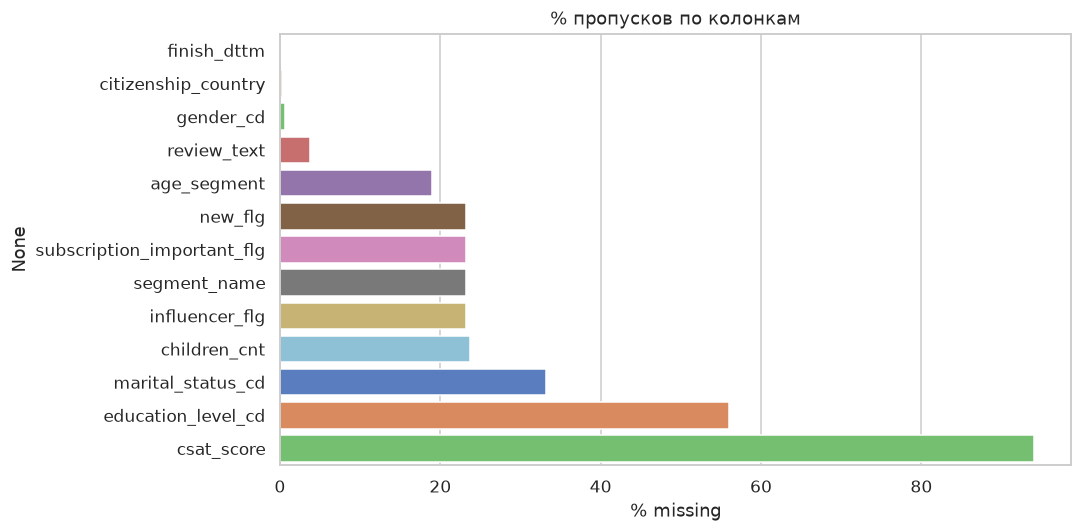

In [10]:
p = pct_missing[pct_missing > 0]
sns.barplot(x=p.values, y=p.index, hue=p.index, palette='muted', legend=False)
plt.title('% пропусков по колонкам')
plt.xlabel('% missing')
plt.tight_layout()

# 4. Целевая переменная
**Правило из постановки:** детрактор = оценка 1–3 либо негативная эмоция без оценки.

In [11]:
df['review_mark'].value_counts(dropna=False)

review_mark
5                           33785
1                            9991
без оценки (негативный)      8954
без оценки (нейтральный)     1782
2                            1096
4                             590
3                             475
без оценки (позитивный)       147
Name: count, dtype: int64

In [12]:
df['review_emotion'].value_counts(dropna=False)

review_emotion
Позитивный    34522
Негативный    22298
Name: count, dtype: int64

In [13]:
df['review_mark_num'] = pd.to_numeric(df['review_mark'], errors='coerce')

is_detractor = ((df['review_mark_num'] <= 3) & df['review_mark_num'].notna()) | \
               (df['review_emotion'] == 'негативный')
df['target'] = is_detractor.astype(int)

n = len(df)
counts = df['target'].value_counts()
print(f"детракторы:  {counts.get(1,0):6d}  ({counts.get(1,0)/n:.1%})")
print(f"не-детракторы: {counts.get(0,0):6d}  ({counts.get(0,0)/n:.1%})")

детракторы:   11562  (20.3%)
не-детракторы:  45258  (79.7%)


## Утечка таргета
Оценка и эмоция полностью определяют таргет → исключаются из признаков. Проверка правила:

In [14]:
pd.crosstab(df['review_emotion'], df['review_mark'], normalize='columns').round(3)

review_mark,1,2,3,4,5,без оценки (негативный),без оценки (нейтральный),без оценки (позитивный)
review_emotion,,,,,,,,
Негативный,1.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
Позитивный,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0


# 5. Распределения категориальных признаков

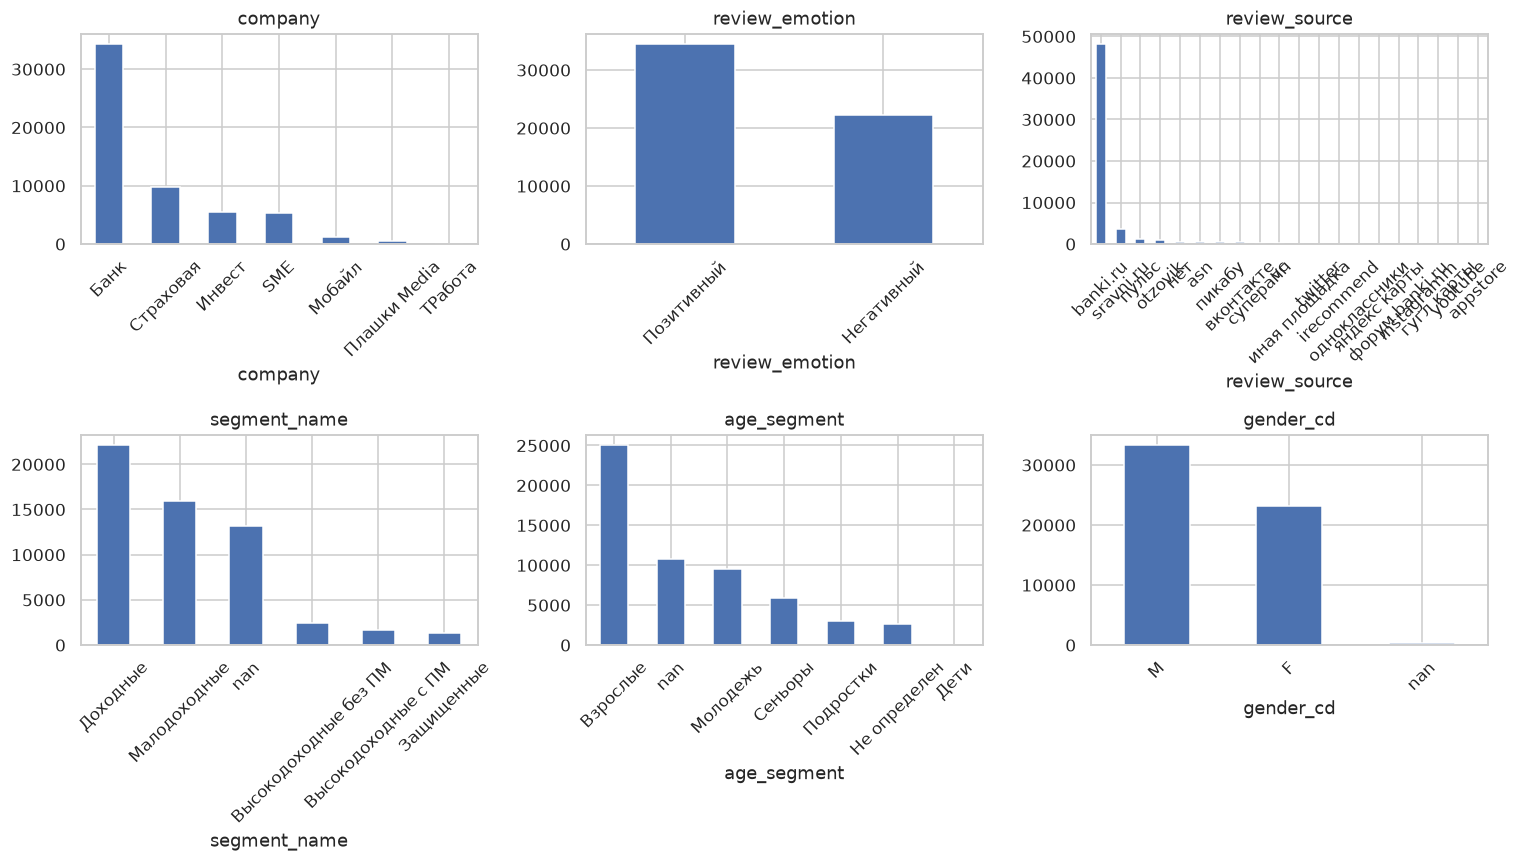

In [15]:
cat_cols = ['company', 'review_emotion', 'review_source', 'segment_name', 'age_segment', 'gender_cd']
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for col, ax in zip(cat_cols, axes.ravel()):
    df[col].value_counts(dropna=False).plot(kind='bar', ax=ax, title=col)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()

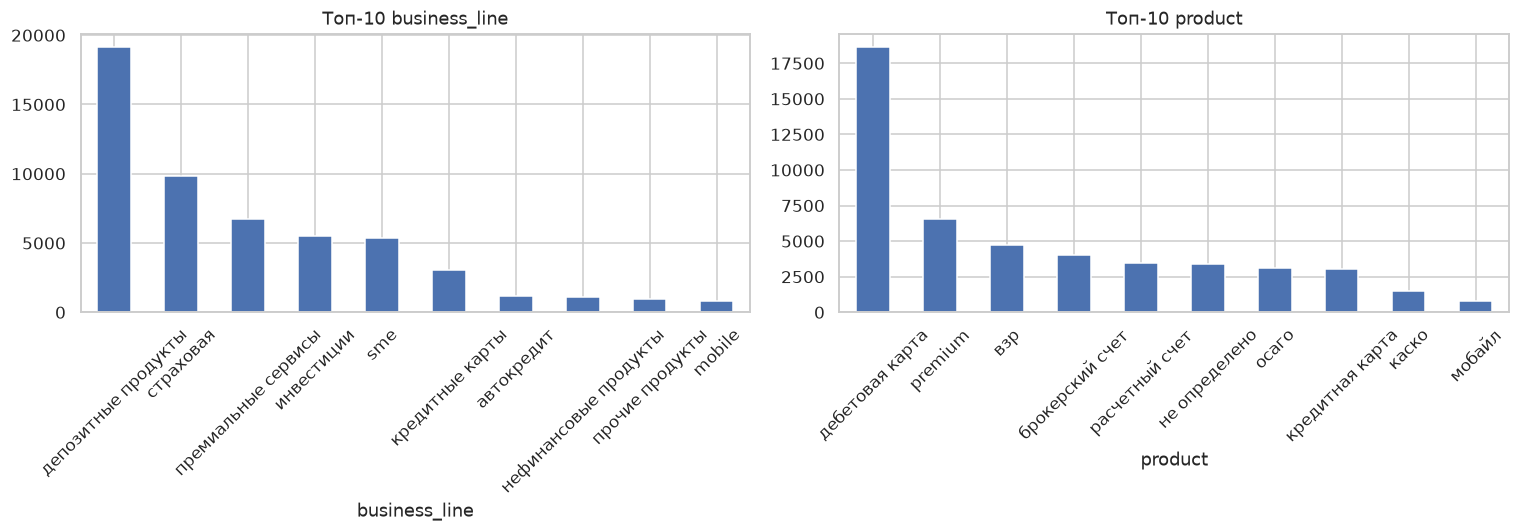

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df['business_line'].value_counts().head(10).plot(kind='bar', ax=axes[0], title='Топ-10 business_line')
df['product'].value_counts().head(10).plot(kind='bar', ax=axes[1], title='Топ-10 product')
for ax in axes: ax.tick_params(axis='x', rotation=45)
plt.tight_layout()

## Базовая тональность по источникам
Проверка гипотезы курсовой: источники имеют разную базовую тональность.

review_emotion,Негативный,Позитивный
review_source,,
appstore,1.000,0.000
asn,0.044,0.956
banki.ru,0.360,0.640
instagramm,0.500,0.500
irecommend,0.719,0.281
otzovik,0.750,0.250
sravni.ru,0.198,0.802
twitter,1.000,0.000
vc,0.996,0.004


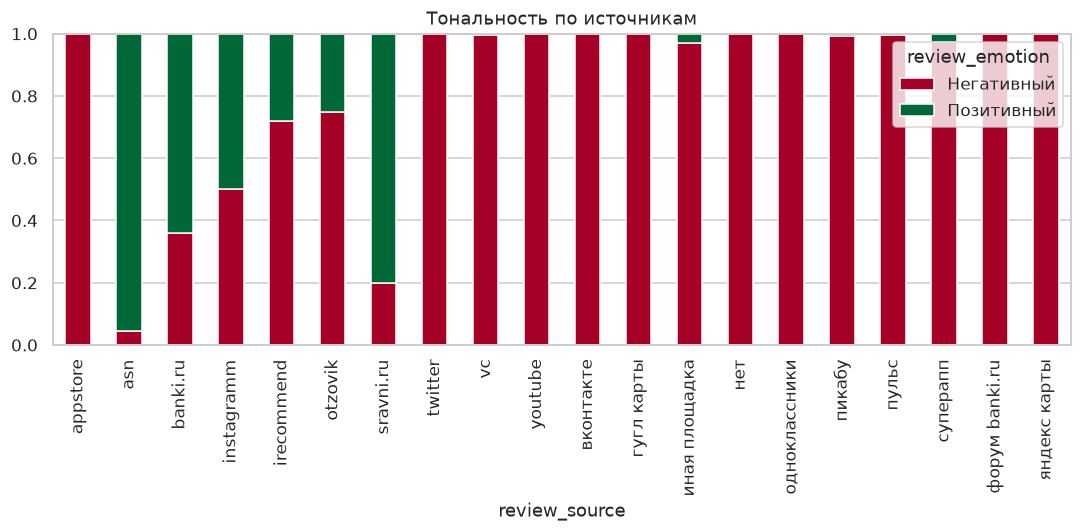

In [17]:
src_emo = pd.crosstab(df['review_source'], df['review_emotion'], normalize='index').round(3)
display(src_emo)
src_emo[['Негативный', 'Позитивный']].plot(kind='bar', stacked=True, colormap='RdYlGn', title='Тональность по источникам')
plt.tight_layout()

# 6. Темпоральный анализ
База для разбиения по датам (train/valid/test по времени публикации).

период: 2025-01-01 00:00:01 — 2025-11-05 22:16:00


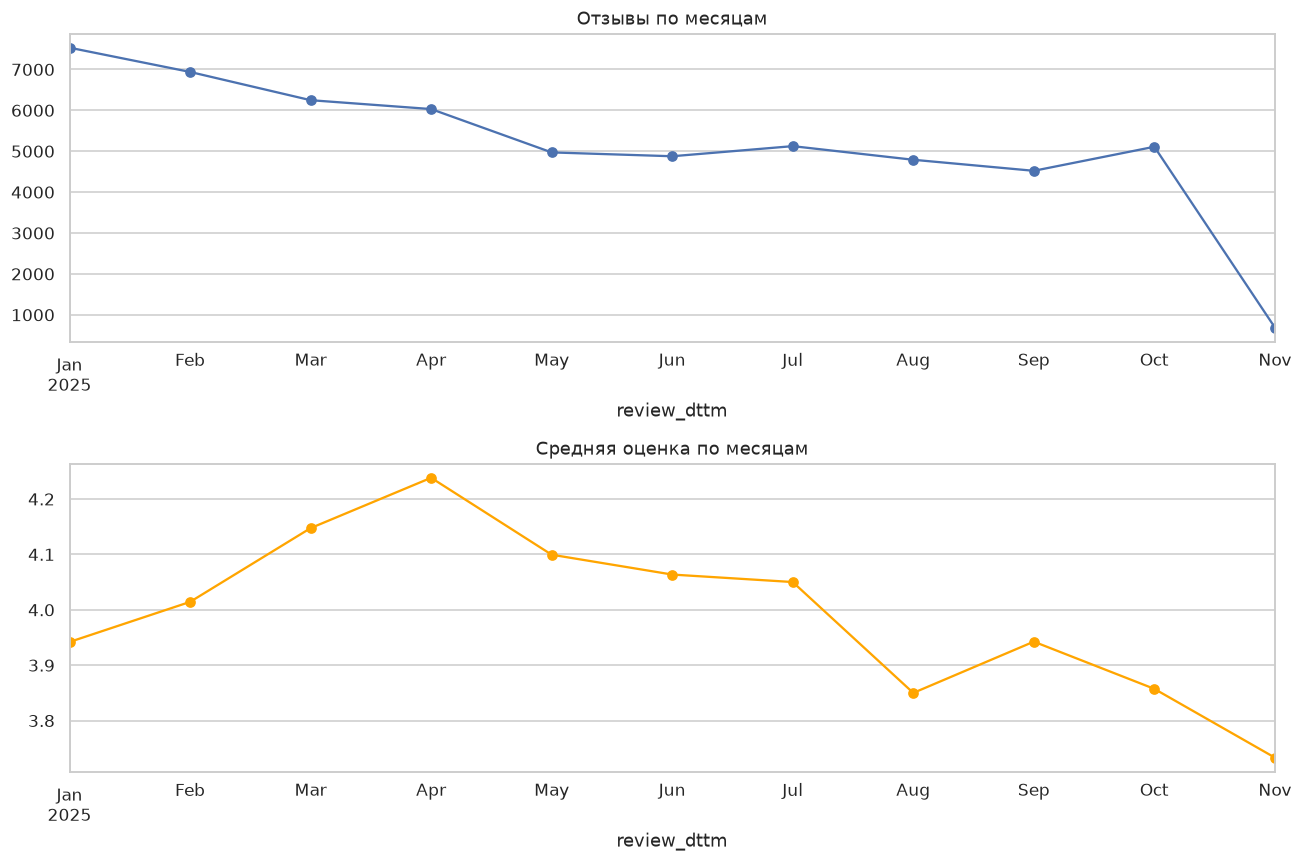

In [18]:
df['review_dttm'] = pd.to_datetime(df['review_dttm'])
monthly = df.set_index('review_dttm').resample('ME').agg(
    reviews=('id_client', 'size'),
    avg_mark=('review_mark_num', 'mean'))

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
monthly['reviews'].plot(ax=axes[0], title='Отзывы по месяцам', marker='o')
monthly['avg_mark'].plot(ax=axes[1], title='Средняя оценка по месяцам', color='orange', marker='o')
plt.tight_layout()
print('период:', df['review_dttm'].min(), '—', df['review_dttm'].max())

# 7. Bivariate анализ

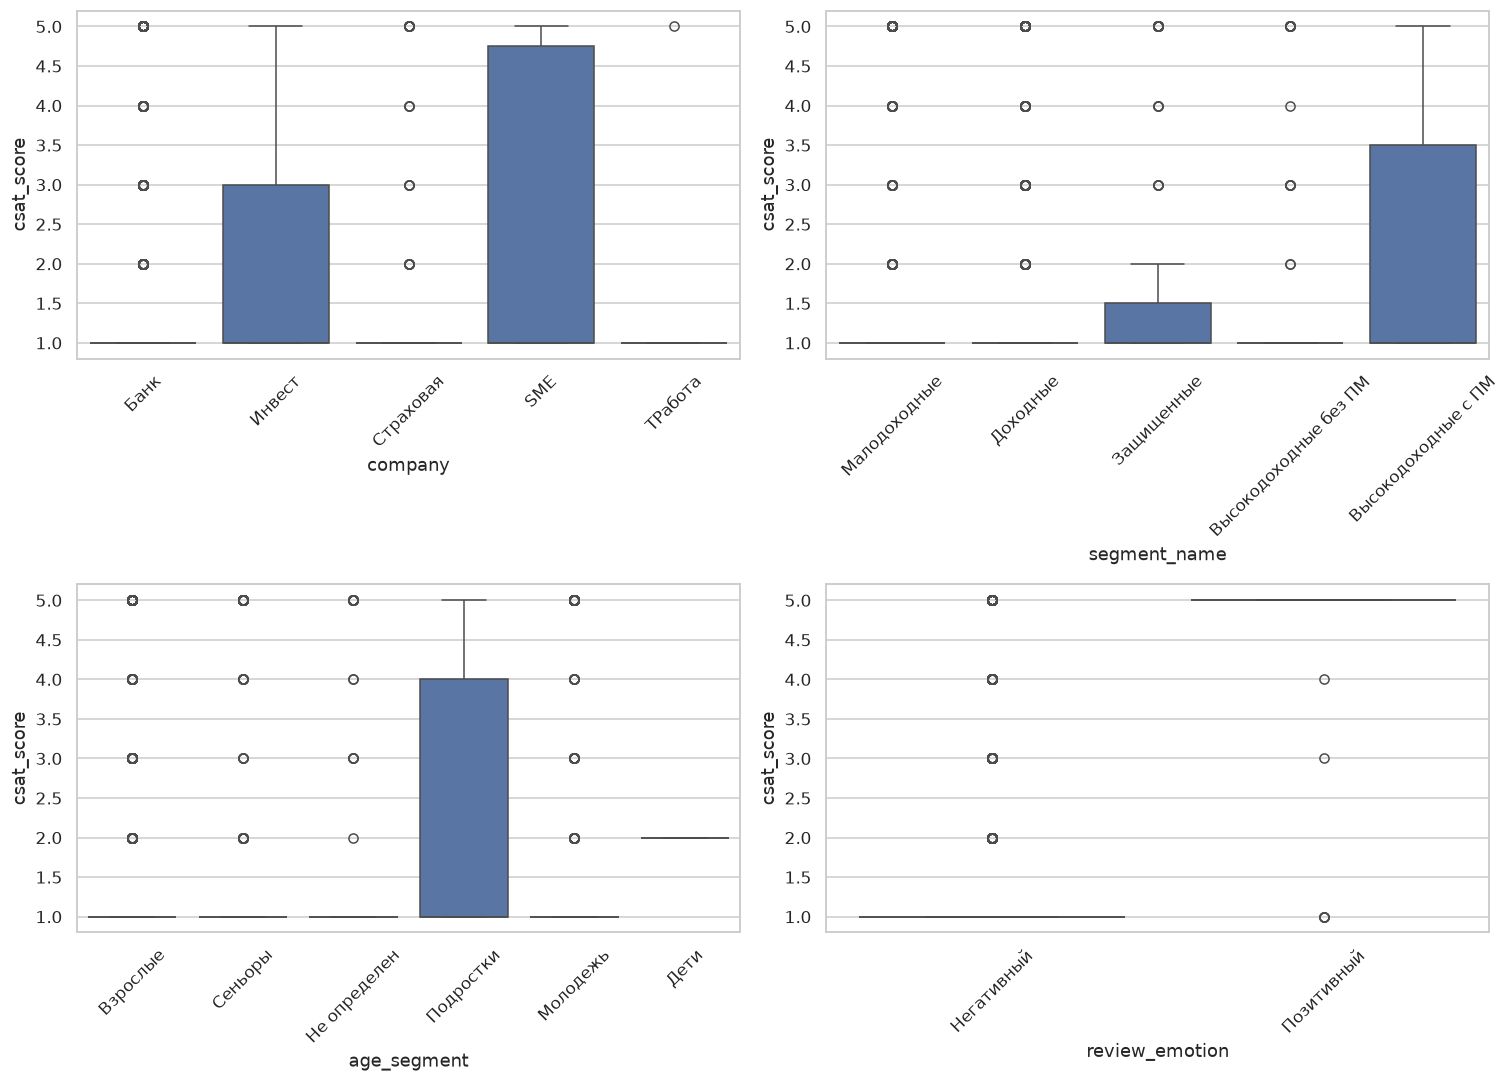

In [19]:
csat = df.dropna(subset=['csat_score'])
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for col, ax in zip(['company','segment_name','age_segment','review_emotion'], axes.ravel()):
    sns.boxplot(data=csat, x=col, y='csat_score', ax=ax)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()

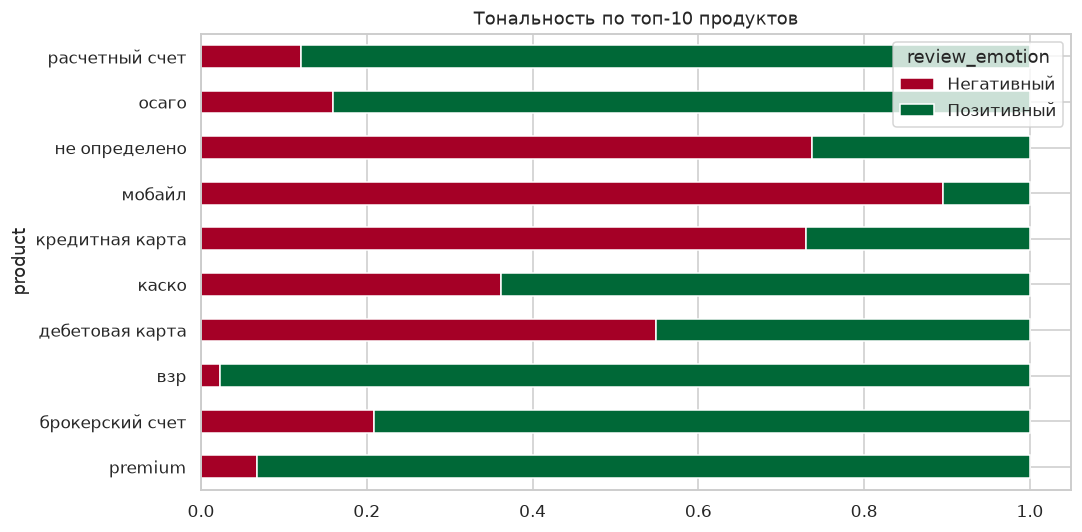

In [20]:
top_products = df['product'].value_counts().head(10).index
prod_sent = df[df['product'].isin(top_products)].groupby('product')['review_emotion'].value_counts(normalize=True).unstack()
prod_sent.plot(kind='barh', stacked=True, title='Тональность по топ-10 продуктов', colormap='RdYlGn')
plt.tight_layout()

# 8. Тексты отзывов

In [21]:
df['text_len'] = df['review_text'].str.len()
df['text_len'].describe()

count    54723.000000
mean       622.274199
std        465.405328
min          1.000000
25%        331.000000
50%        455.000000
75%        762.000000
max       4000.000000
Name: text_len, dtype: float64

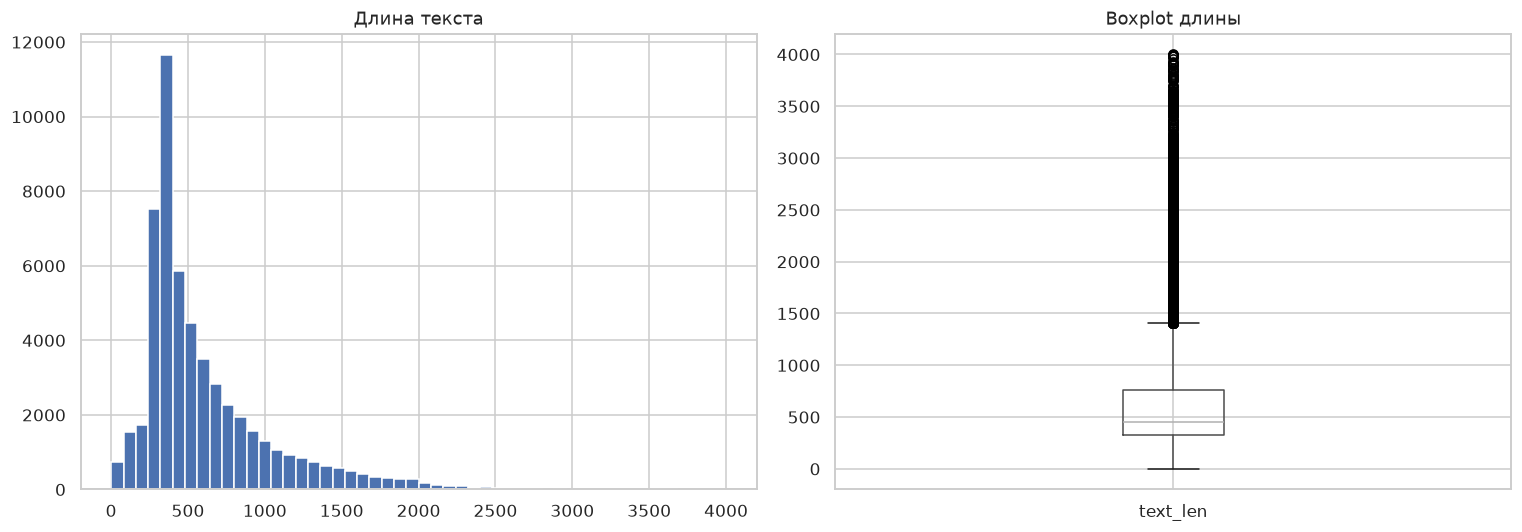

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df['text_len'].hist(bins=50, ax=axes[0]); axes[0].set_title('Длина текста')
df.boxplot(column='text_len', ax=axes[1]); axes[1].set_title('Boxplot длины')
plt.tight_layout()

# 9. Выводы EDA и требования к качеству данных

## Выводы
1. **Объём и структура**: 56 820 записей, 25 колонок; полных дубликатов — 0; дубликатов текстов (норм. регистр) — 2 750.
2. **Таргет**: детракторы — 11 562 (20,3%), не-детракторы — 45 258 (79,7%) → умеренный дисбаланс, классовые веса на train; `review_mark` и `review_emotion` исключаются из признаков (утечка таргета).
3. **Пропуски**: `csat_score` заполнен лишь у ~6% → непригоден как таргет (бизнес-контекстная метрика); `education_level_cd` — 56%, `marital_status_cd` — 33%, сегментные флаги и `children_cnt` — ~23-24% — структурные пропуски, нужна единая стратегия заполнения train/inference; `review_text` пуст у 3,7%.
4. **Категориальные**: высокая кардинальность у `product`/`reason`/`review_theme`/`subtheme` → риск неизвестных категорий в инференсе.
5. **Источники**: 20 значений, `banki.ru` — 85% записей; базовая тональность по источникам различается → срез-анализ качества по источникам обязателен.
6. **Время**: период 2025-01-01 — 2025-11-05 (~10 месяцев) → разбиение train/valid/test строго по датам публикации (последний месяц — тест).

## Требования к качеству данных (блокируют обучение)
| № | Требование | Порог / правило | Обоснование |
|---|---|---|---|
| 1 | Отсутствие утечки | `review_mark`, `review_emotion`, `csat_score` — вне списка признаков | таргет детерминирован этими колонками |
| 2 | Целостность таргета | `target` определён для 100% записей обучающей выборки | записи с незавершённой обработкой — не включать |
| 3 | Пропуски в категориальных | явная категория `unknown` вместо NaN | одинаковость train/inference |
| 4 | Неизвестные категории в инференсе | доля новых значений < 5% | иначе — триггер переобучения |
| 5 | Дедупликация текстов | 2 750 дублей убрать до разбиения выборок | исключить попадание одинаковых отзывов в train и test |
| 6 | Валидность дат | `finish_dttm >= review_dttm`; разбиение по `review_dttm` | имитация эксплуатации: обучение на прошлом, тест на будущем |
| 7 | Дисбаланс | классовые веса только на train; тест не изменяется | сохранение реального распределения при оценке |